# Study 05 — Genetic Programming (GP)

Exploratory study notebook for the fifth algorithm. GP is different from the other four: it does not tune a
fixed set of numbers — it **evolves the control law itself** as an expression tree. That is why, in the final
system, the GP optimiser only drives the GP controller.

**Questions**
1. Can GP rediscover a known formula? (symbolic-regression sanity check)
2. Which GP hyper-parameters matter?
3. Population vs generations at a fixed budget.
4. What control laws does it evolve for each plant, and how good are they?
5. Is tree-aware search actually better than DE/GA/PSO/SA searching the *same* tree encoding?

All closed-loop runs use the project's simulator, metrics and objective. ⏱ About 3 minutes.

## The algorithm

* **Representation:** a tree over the terminals $e$, $\dot e$ (`de`), $\int e$ (`ie`) and constants, with functions
  $+,\ -,\ \times,\ \div_{protected},\ \tanh$; maximum depth 3. A complete PID law
  $K_p e + K_i \int e + K_d \dot e$ fits exactly.
* **Initialisation:** ramped half-and-half (mix of full and grown trees of depth 1–3).
* **Variation:** subtree crossover (swap random sub-trees between parents), subtree / point / constant mutation.
* **Selection:** tournament; the best tree survives unchanged (elitism).
* **Encoding:** every tree maps to a 30-gene vector (symbol + constant per slot of a complete binary tree).
  That vector is what DE/GA/PSO/SA search when they tune the GP controller — without tree-aware operators.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from study_utils import *
from smart_control.optimizers.genetic_programming import GeneticProgramming
from smart_control.optimizers.differential_evolution import DifferentialEvolution
from smart_control.optimizers.genetic_algorithm import GeneticAlgorithm
from smart_control.optimizers.particle_swarm import ParticleSwarmOptimization
from smart_control.optimizers.simulated_annealing import SimulatedAnnealing
from smart_control.gp_tree import DEFAULT_GRAMMAR, decode_vector, evaluate_tree, tree_to_string, tree_size

KEY, COLOR = "GP", OPT_COLORS["GP"]
print("Implementation defaults:")
for k, v in GeneticProgramming().default_settings().items():
    print(f"  {k:22s} {v}")
print("\nGrammar:", DEFAULT_GRAMMAR)

Implementation defaults:
  population_size        30
  max_iterations         100
  random_seed            42
  tournament_size        5
  crossover_rate         0.8
  mutation_rate          0.3
  elite_count            1
  internal_point_prob    0.9
  const_sigma_ratio      0.1
  max_size               None
  parsimony_coeff        0.0
  max_evaluations        None
  target_fitness         None
  use_cache              True
  grammar                None

Grammar: GPGrammar(functions=('add', 'sub', 'mul', 'div', 'tanh'), variables=('e', 'de', 'ie'), const_range=(-10.0, 10.0), max_depth=3)


## 1. Sanity check: rediscover a known law

Target: $u = 2e + 0.5\int e$ — a PI law. We sample random $(e, \dot e, \int e)$ points and ask GP to minimise the
RMS error between its tree and the target. If GP cannot find a simple formula with no noise, it will not
find a good controller either.

seed 0: RMS error 0.1789   u = (e + (tanh(ie) + (e - 0.03599)))


seed 1: RMS error 0.1792   u = (e + (tanh(ie) + e))


seed 2: RMS error 0.1459   u = (tanh(tanh(ie)) + (e + e))


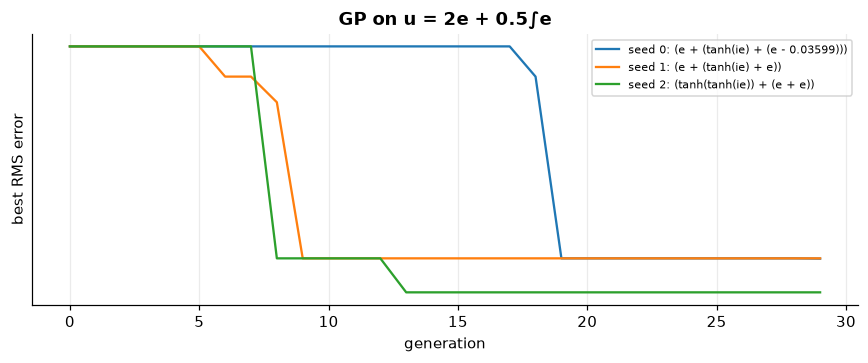

In [2]:
rng = np.random.default_rng(0)
SAMPLES = rng.uniform(-2, 2, size=(80, 3))
target = 2 * SAMPLES[:, 0] + 0.5 * SAMPLES[:, 2]
bounds = DEFAULT_GRAMMAR.parameter_bounds()

def regression_error(vector):
    tree = decode_vector(vector)
    pred = np.array([evaluate_tree(tree, {"e": a, "de": b, "ie": c}) for a, b, c in SAMPLES])
    err = float(np.sqrt(np.mean((pred - target) ** 2)))
    return err if np.isfinite(err) else 1e6

fig, ax = plt.subplots(figsize=(8, 3.4))
for seed in (0, 1, 2):
    res = GeneticProgramming().optimize(regression_error, bounds,
                                        settings={"population_size": 60, "max_iterations": 30, "random_seed": seed})
    ax.plot(res.convergence_history, label=f"seed {seed}: {res.metadata['best_expression']}")
    print(f"seed {seed}: RMS error {res.best_fitness:.4f}   u = {res.metadata['best_expression']}")
ax.set_yscale("symlog", linthresh=1e-3)
ax.set(xlabel="generation", ylabel="best RMS error", title="GP on u = 2e + 0.5∫e")
ax.legend(fontsize=7.5)
plt.tight_layout(); plt.show()

## 2. Hyper-parameter study

**Test case:** the GP controller on the 2nd-order plant, ≈60 evaluations, 3 seeds. Mean J (± std) per setting.

### 2a. Tournament size × mutation rate

27 runs in 31 s


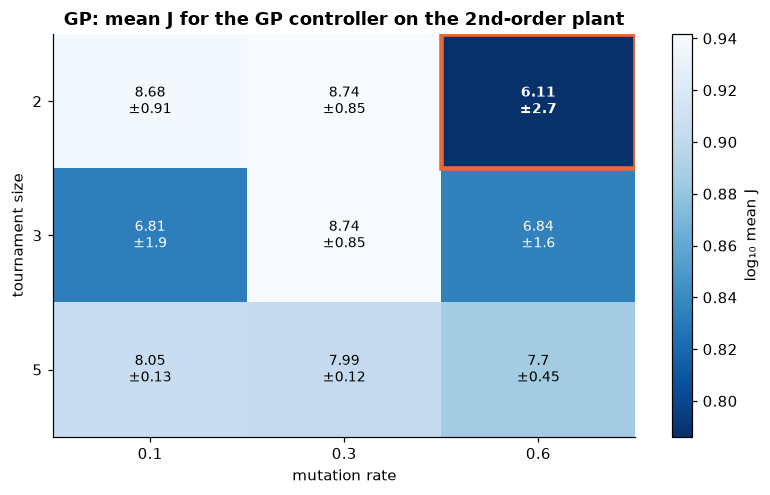

Best: tournament = 2, mutation = 0.6  ->  mean J = 6.112


In [3]:
ROWS, COLS = [2, 3, 5], [0.1, 0.3, 0.6]
mean, std = sweep2d(GeneticProgramming, budget(KEY, 10, 5), "tournament_size", ROWS, "mutation_rate", COLS,
                    controller="GP Controller", plant="second_order")
i, j = sweep_heatmap(mean, ROWS, COLS, "tournament size", "mutation rate",
                     "GP: mean J for the GP controller on the 2nd-order plant", std=std)
print(f"Best: tournament = {ROWS[i]}, mutation = {COLS[j]}  ->  mean J = {mean[i, j]:.4g}")

### 2b. Crossover rate
How much of each generation is built by recombining sub-trees (the rest is copied, then possibly mutated).

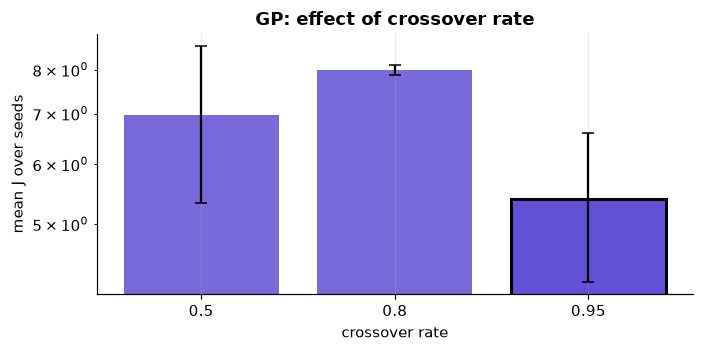

crossover = 0.5   mean J = 6.97 ± 1.6
crossover = 0.8   mean J = 7.994 ± 0.12
crossover = 0.95   mean J = 5.394 ± 1.2


In [4]:
VALUES = [0.5, 0.8, 0.95]
m1, s1 = sweep1d(GeneticProgramming, budget(KEY, 10, 5), "crossover_rate", VALUES,
                 controller="GP Controller", plant="second_order")
plot_sweep1d(VALUES, m1, s1, "crossover rate", COLOR, "GP: effect of crossover rate")
for v, m, sd in zip(VALUES, m1, s1):
    print(f"crossover = {v}   mean J = {m:.4g} ± {sd:.2g}")

## 3. Population vs generations at a fixed budget (120 evaluations)

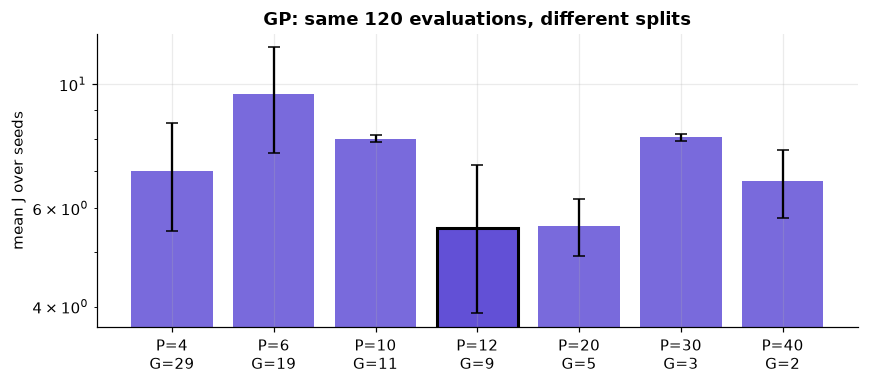

P =  4, G = 29   mean J = 6.992 ± 1.5
P =  6, G = 19   mean J = 9.594 ± 2.1
P = 10, G = 11   mean J = 7.994 ± 0.12
P = 12, G =  9   mean J = 5.539 ± 1.6
P = 20, G =  5   mean J = 5.583 ± 0.66
P = 30, G =  3   mean J = 8.039 ± 0.13
P = 40, G =  2   mean J = 6.702 ± 0.94


In [5]:
SPLITS = [(4, 29), (6, 19), (10, 11), (12, 9), (20, 5), (30, 3), (40, 2)]
means, stds = [], []
for p, g in SPLITS:
    js = [run(GeneticProgramming, "GP Controller", "second_order", budget(KEY, p, g), seed)["best_fitness"]
          for seed in (42, 43, 44)]
    means.append(np.mean(js)); stds.append(np.std(js))
plot_budget_split(SPLITS, means, stds, COLOR, "GP: same 120 evaluations, different splits")
for (p, g), m, sd in zip(SPLITS, means, stds):
    print(f"P = {p:2d}, G = {g:2d}   mean J = {m:.4g} ± {sd:.2g}")

## 4. The GP controller on every plant

≈60 evaluations (population 10 × 5 generations), implementation defaults, seeds 42–44.

In [6]:
records = run_matrix(GeneticProgramming, ["GP Controller"], PLANT_NAMES, budget(KEY, 10, 5), seeds=(42, 43, 44))

GP Controller   2nd order seed 42  J =     7.979  IAE =    1.65  settled = yes  (1.4 s)


GP Controller   2nd order seed 43  J =     8.144  IAE =    1.62  settled = yes  (1.3 s)


GP Controller   2nd order seed 44  J =     7.859  IAE =    2.56  settled = yes  (1.6 s)


GP Controller   3rd order seed 42  J =     23.38  IAE =    1.78  settled = yes  (1.5 s)


GP Controller   3rd order seed 43  J =     16.98  IAE =    1.94  settled = yes  (1.9 s)


GP Controller   3rd order seed 44  J =       8.2  IAE =    4.65  settled = yes  (2.2 s)


GP Controller   4th order seed 42  J =        33  IAE =    8.66  settled = no   (1.5 s)


GP Controller   4th order seed 43  J =     28.49  IAE =    4.45  settled = no   (1.7 s)


GP Controller   4th order seed 44  J =        33  IAE =    8.66  settled = no   (1.7 s)

9 runs in 15 s


In [7]:
summary_table(records)

Controller      Plant        J mean    ± std  settled     IAE  Ts (s)  Tr (s)    OS %      Ess
----------------------------------------------------------------------------------------------
GP Controller   2nd order     7.994    0.117     3/3    2.56    12.1    2.56    3.31   0.0152
GP Controller   3rd order     16.19     6.22     3/3    4.65    9.36    5.51    1.47  0.00171
GP Controller   4th order      31.5     2.13     0/3    4.45       —    4.84       0   0.0431


### The evolved control laws (best seed per plant)

2nd order  u = (((ie - e) / (e - e)) * tanh((ie + de)))   (12 nodes)
3rd order  u = (((de / de) / (7.49 / ie)) * tanh((ie + de)))   (12 nodes)
4th order  u = (e / (e * 1.63))   (5 nodes)


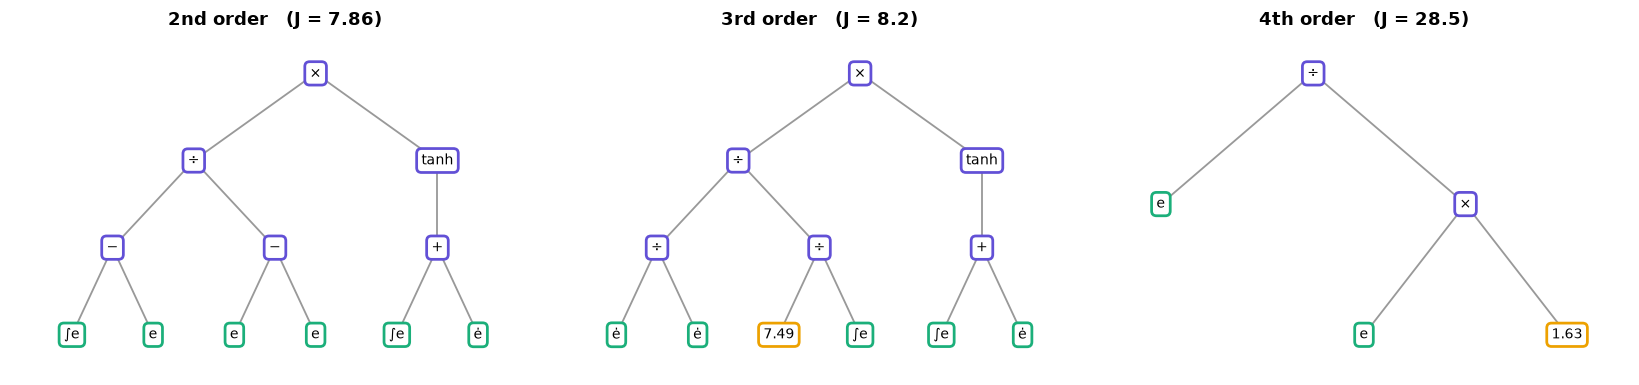

In [8]:
best = best_by_cell(records)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, plant in zip(axes, PLANT_NAMES):
    r = best[("GP Controller", plant)]
    tree = decode_vector(r["best_solution"])
    draw_tree(tree, ax, f"{PLANT_LABELS[plant]}   (J = {r['best_fitness']:.3g})")
    print(f"{PLANT_LABELS[plant]:9s}  u = {tree_to_string(tree, 3)}   ({tree_size(tree)} nodes)")
plt.tight_layout(); plt.show()

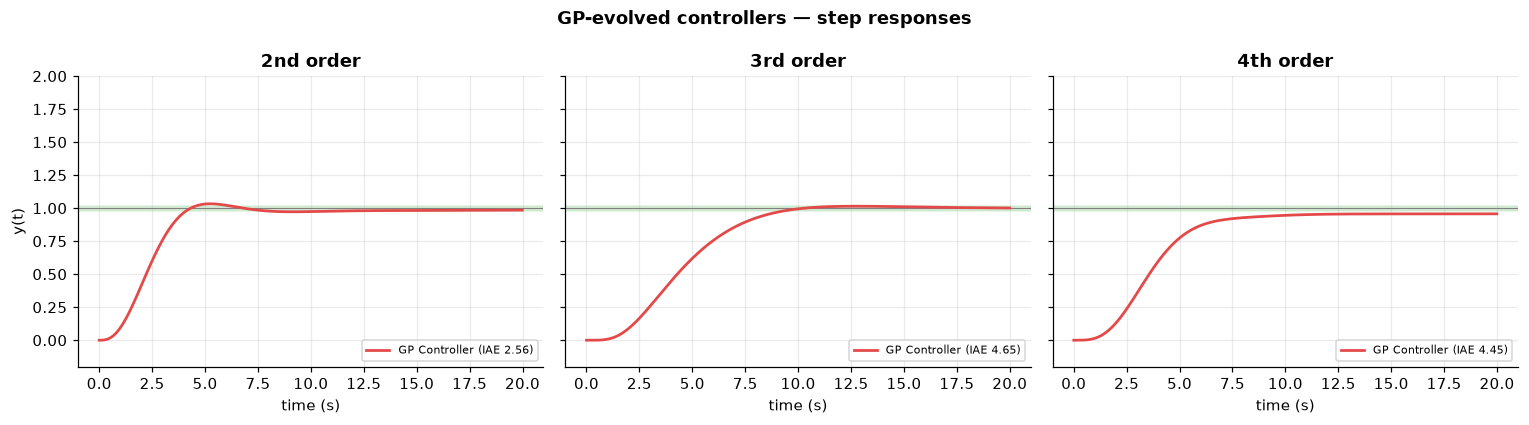

In [9]:
plot_step_grid(records, "GP-evolved controllers — step responses")

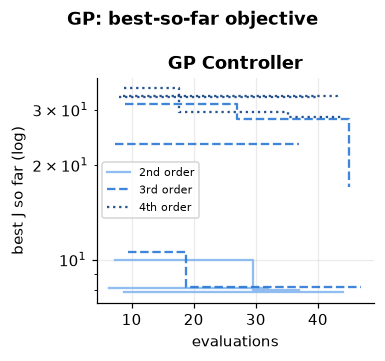

In [10]:
plot_convergence_grid(records, COLOR, "GP: best-so-far objective")

## 5. Tree-aware search vs numeric search on the same encoding

DE, GA, PSO and SA can also tune the GP controller — they search the 30-gene vector directly.
Same budget (≈60 evaluations), same seeds. Is GP's tree-aware crossover worth it?

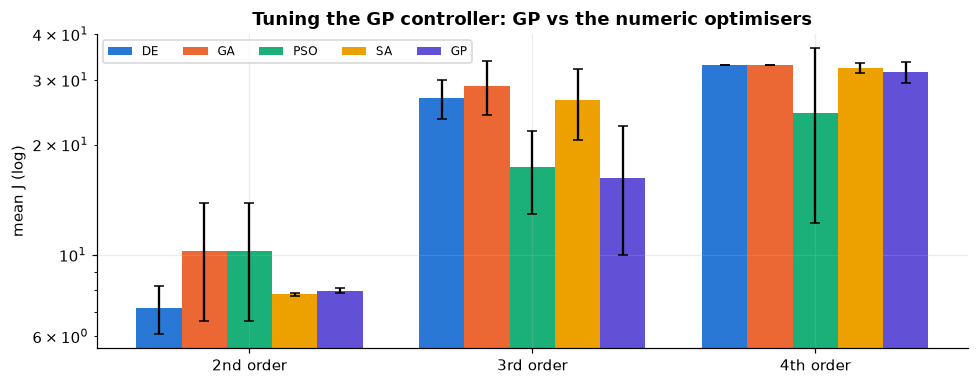

                  2nd order             3rd order             4th order
DE           7.157 (3/3 set.)        26.77 (1/3 set.)           33 (0/3 set.)
GA           10.23 (3/3 set.)        28.92 (1/3 set.)           33 (0/3 set.)
PSO          10.23 (3/3 set.)        17.34 (3/3 set.)        24.38 (1/3 set.)
SA           7.797 (3/3 set.)        26.38 (1/3 set.)        32.34 (0/3 set.)
GP           7.994 (3/3 set.)        16.19 (3/3 set.)         31.5 (0/3 set.)


In [11]:
OTHERS = {"DE": DifferentialEvolution, "GA": GeneticAlgorithm, "PSO": ParticleSwarmOptimization,
          "SA": SimulatedAnnealing, "GP": GeneticProgramming}
cmp = {}
for name, cls in OTHERS.items():
    for plant in PLANT_NAMES:
        js = [run(cls, "GP Controller", plant, budget(name, 10, 5), seed) for seed in (42, 43, 44)]
        cmp[(name, plant)] = js

fig, ax = plt.subplots(figsize=(9, 3.6))
width = 0.16
for k, name in enumerate(OTHERS):
    m = [np.mean([r["best_fitness"] for r in cmp[(name, p)]]) for p in PLANT_NAMES]
    sd = [np.std([r["best_fitness"] for r in cmp[(name, p)]]) for p in PLANT_NAMES]
    ax.bar(np.arange(3) + (k - 2) * width, m, width, yerr=sd, capsize=3, color=OPT_COLORS[name], label=name)
ax.set_xticks(range(3), [PLANT_LABELS[p] for p in PLANT_NAMES])
ax.set(ylabel="mean J (log)", yscale="log", title="Tuning the GP controller: GP vs the numeric optimisers")
ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'':5s}" + "".join(f"{PLANT_LABELS[p]:>22s}" for p in PLANT_NAMES))
for name in OTHERS:
    row = ""
    for p in PLANT_NAMES:
        rs = cmp[(name, p)]
        row += f"{np.mean([r['best_fitness'] for r in rs]):>13.4g} ({sum(r['settled'] for r in rs)}/3 set.)"
    print(f"{name:5s}{row}")

## Takeaways

**1. Sanity check — partial success.** GP did *not* recover u = 2e + 0.5∫e exactly. Every seed found the right **structure** — 2e plus a function of ∫e — but approximated 0.5·∫e with tanh(∫e) (RMS error ≈ 0.15–0.18). Within ±2 the two are similar, and constants only change through mutation, so exact coefficients are hard to reach in 30 generations.

**2. Hyper-parameters:** best **tournament size 2 with mutation rate 0.6** (J ≈ 6.1) — weak selection pressure plus heavy mutation keeps the population diverse. **Crossover rate 0.95** was best (J ≈ 5.4). The budget-split study shows **no clear trend** (J 5.5–9.6, noisy): at this budget GP is dominated by luck in the initial trees.

**3. The evolved laws are often degenerate — the most important finding.** Protected division returns **1** when the denominator is ≈ 0, and GP exploits it:
- 2nd order: `((ie − e)/(e − e)) · tanh(ie + de)` — the first factor is *always* 1, so the law is really **u = tanh(∫e + ė)**: a saturated PI-like law that does work (all seeds settle).
- 4th order: `e/(1.63·e)` = **a constant u ≈ 0.61** — no feedback at all. The plant's DC gain (1.56) then gives y ≈ 0.96, just outside the ±2 % band. This same constant law is why **J = 33.0 appears identically** for the GP controller under DE, GA and SA.

**4. Tree-aware vs numeric search on the same encoding (≈60 evals, 3 seeds):**
- **3rd-order plant: GP is best** (J ≈ 16.2, 3/3 settle) together with PSO (J ≈ 17.3, 3/3); DE, GA and SA settle only 1/3.
- **2nd-order plant:** all methods settle; DE and SA are slightly better (J ≈ 7.2 / 7.8 vs 8.0).
- **4th-order plant:** nobody really succeeds; only PSO settles one seed.

**Implications for the full system:** GP's tree operators do help on the harder plant, but the grammar lets it "cheat" with constant laws. Worth considering: a validity check that the tree actually uses `e` (`gp_tree.uses_variable` exists for this), a parsimony penalty, and protected division returning 0 instead of 1.